# 技术研究伴随文档 · 2026-10-19

**Team87 · Chengxuan YUAN · Lebmar**

这是模型开发、审计与负面证据的可复现companion，不是参赛论文。只读取冻结开发结果；不运行新模型、不拟合、不读取原始市场CSV或121–180最终值。

## tl;dr

本轮比较V2、V2b与V3。初始覆盖、投入后的普通服务持续性、回撤与收益分别衡量；不能把“初始全投入”解释为“持续自动服务”。以下数字由保存结果在执行时读取并核验。

In [1]:
from pathlib import Path
import sys, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT/'scripts/build_technical_rebuild_companion.py').exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT/'scripts'))
from build_technical_rebuild_companion import prepare_data
state = prepare_data(); tables=state['tables']; meta=state['meta']; colors=state['colors']; assets=state['assets']
plt.rcParams.update({'font.family':'Arial Unicode MS','font.size':12,'axes.titlesize':15,'axes.labelsize':12,'xtick.labelsize':12,'ytick.labelsize':12,'legend.fontsize':12,'figure.facecolor':'white','axes.facecolor':'white','svg.fonttype':'none','axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'axes.axisbelow':True,'savefig.facecolor':'white'})
def finish(fig, name, source):
    fig.tight_layout(); fig.savefig(assets/(name+'.png'),dpi=240,bbox_inches='tight'); fig.savefig(assets/(name+'.svg'),bbox_inches='tight')
    source.to_csv(assets/(name+'_data.csv'),index=False)
    display(fig); plt.close(fig)
    display(Markdown('图数据：`'+name+'_data.csv`；输入SHA256见同目录 `source_manifest.json`。'))
pd.set_option('display.max_columns',12)


In [2]:
q=tables['admission'].set_index('version'); display(Markdown(f"V2初始投入 **{int(q.loc['V2','financial_n'])}/120**；V2b与V3均为 **120/120**。其OOF普通服务期平均比例分别为 **{q.loc['V2b','mean_automatic_fraction']:.1%} / {q.loc['V3','mean_automatic_fraction']:.1%}**；中位CAGR为 **{q.loc['V2b','median_cagr']:.2%} / {q.loc['V3','median_cagr']:.2%}**。低回撤伴随转介与收益代价。"))

V2初始投入 **24/120**；V2b与V3均为 **120/120**。其OOF普通服务期平均比例分别为 **28.7% / 29.9%**；中位CAGR为 **2.85% / 2.83%**。低回撤伴随转介与收益代价。

## Context & Methods

### 关键假设与边界

开发情景是合成年度路径。研究已反复使用开发数据，历史最终数据曝光也保留记录；此次OOF划分和复现不会产生新的盲测。原始H、CPI、历史峰值及MDD不重置；实数手续费按买入金额支付一次。无置信区间，无“获奖”或真实未来保护保证。

- V2：一步费后配对增长目标与经验联合支持过滤。
- V2b：首次支持族无可行行动时，仅一次最大化扣费后支持最坏下一期财富，随后进入Review持有。
- V3：只把主要提案的临时目标改为 `a·m·w+(1−a·m)·e_bill`，其中 `m=clip((L−d)/(L(1−d)),0,1)`，`d=1−R/P`；原始9点缓解保持不缩放。

`F=(1−L)P`，预算下限为 `max(F,R−ρ(R−F))`。经验支持上的一步可行，不等于真实未来支持包含、递归可行或全程回撤保证。

## Data

数据源是下列已保存产物；每个读取文件保留SHA256，图旁另存CSV数据。`source_manifest.json`列出全部产物身份。独立审计与同源复现各自提供不同证据。

In [3]:
display(pd.DataFrame(meta['statuses'])[['artifact','status']]); display(Markdown(f"已绑定保存文件 **{len(meta['sources'])}** 个；原始市场读取=0，模型运行=0。压力状态：{meta['stress_status']}。"))

,artifact,status
0,state_budget_rebuild_v1,完成并独立核验
1,state_budget_mitigation_v1,完成并独立核验
2,state_budget_cushion_v1,完成并独立核验
3,state_budget_stability_v1,完成并独立核验
4,state_budget_mitigation_stability_v1,完成并独立核验
5,state_budget_cushion_stability_v1,完成并独立核验
6,state_budget_analysis_v1,完成；保存结果后处理
7,state_budget_mitigation_analysis_v1,完成；保存结果后处理
8,state_budget_cushion_analysis_v1,完成；保存结果后处理
9,q1_stability_diagnostic_v1,完成并独立核验


已绑定保存文件 **190** 个；原始市场读取=0，模型运行=0。压力状态：完成并独立核验。

## Results

### 1. 准入与转介分开看

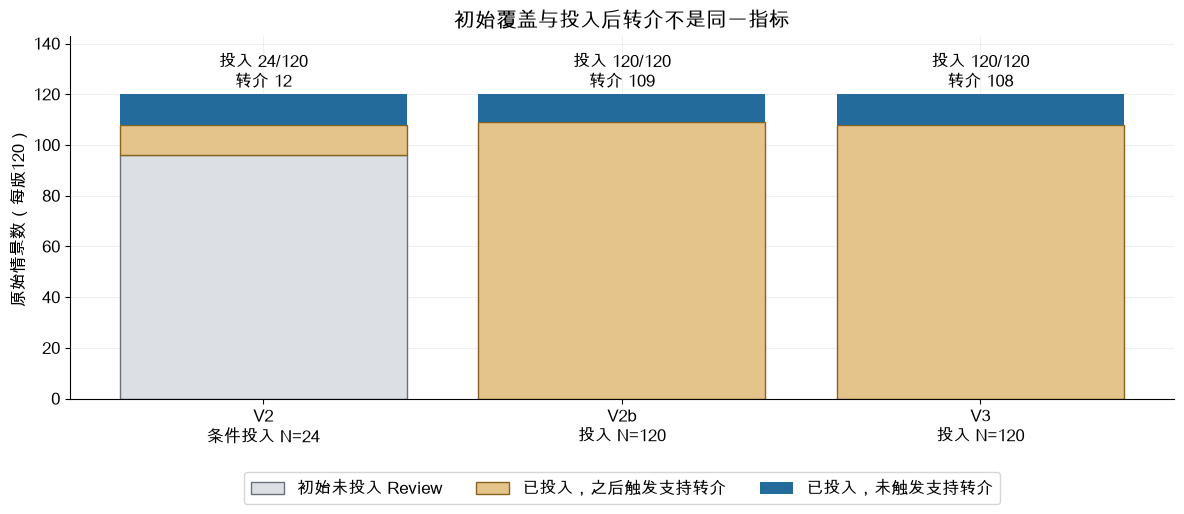

图数据：`01_admission_referral_data.csv`；输入SHA256见同目录 `source_manifest.json`。

**负面结果：** V2 的较高持续服务比例只针对投入的24条路径；不能当作全120条路径的表现。V2b/V3虽全数初始投入，绝大多数路径随后进入转介持有。

In [4]:
d=tables['admission'].set_index('version').loc[['V2','V2b','V3']]
fig,ax=plt.subplots(figsize=(12,5.4)); x=np.arange(3)
initial=120-d.financial_n; referral=d.support_review_n; remaining=d.financial_n-referral
ax.bar(x,initial,color='#DCE0E5',edgecolor='#6A707A',label='初始未投入 Review')
ax.bar(x,referral,bottom=initial,color='#E4C48A',edgecolor='#87631F',label='已投入，之后触发支持转介')
ax.bar(x,remaining,bottom=initial+referral,color='#236B9B',label='已投入，未触发支持转介')
for i,v in enumerate(d.index):
    ax.text(i,123,f"投入 {int(d.loc[v,'financial_n'])}/120\n转介 {int(referral.loc[v])}",ha='center',fontsize=12)
ax.set(xticks=x,xticklabels=['V2\n条件投入 N=24','V2b\n投入 N=120','V3\n投入 N=120'],ylim=(0,143),ylabel='原始情景数（每版120）',title='初始覆盖与投入后转介不是同一指标')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.18),ncol=3);finish(fig,'01_admission_referral',d.reset_index())
display(Markdown('**负面结果：** V2 的较高持续服务比例只针对投入的24条路径；不能当作全120条路径的表现。V2b/V3虽全数初始投入，绝大多数路径随后进入转介持有。'))


### 2. 同一120条路径的收益与回撤分布

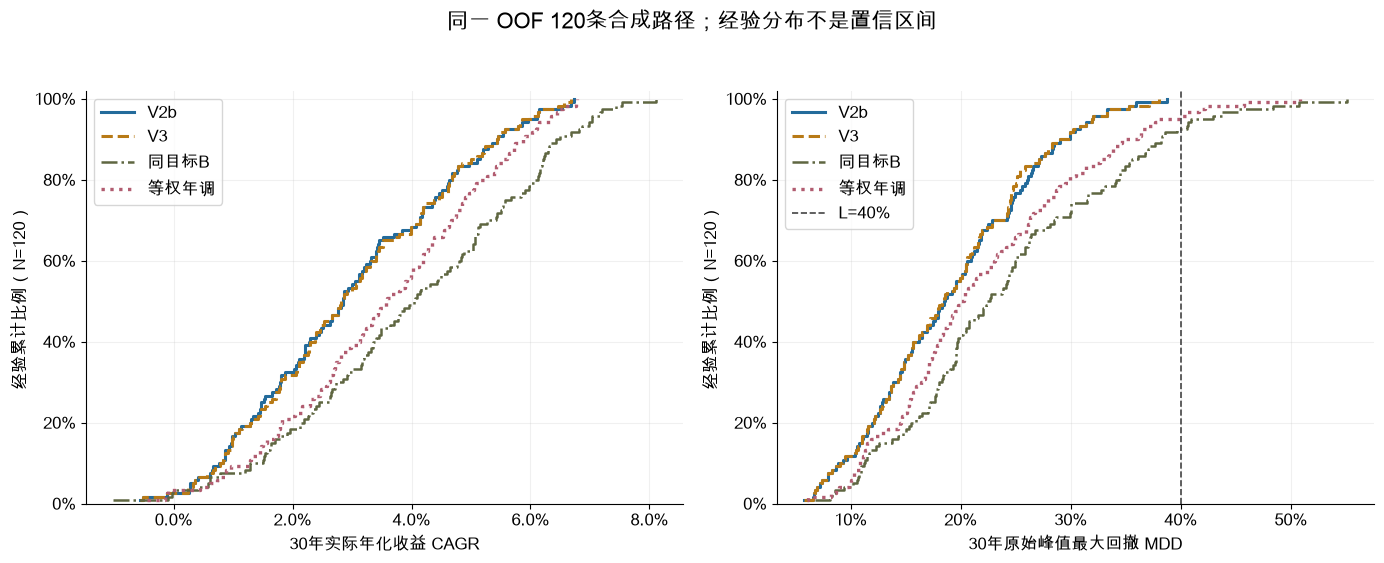

图数据：`02_same120_ecdf_data.csv`；输入SHA256见同目录 `source_manifest.json`。

V2b/V3压低了此开发样本的回撤，也牺牲了收益。这里不加入只投入24条路径的V2，以免混淆比较总体。

In [5]:
d=tables['distribution'];fig,axes=plt.subplots(1,2,figsize=(14,5.4))
styles={'V2b':('-',2.2),'V3':('--',2.2),'同目标B':('-.',1.8),'等权年调':(':',2.4)}
for label in ['V2b','V3','同目标B','等权年调']:
    q=d[d.series==label]
    for ax,key in zip(axes,['cagr','mdd']):
        v=np.sort(q[key]);ax.step(v,np.arange(1,len(v)+1)/len(v),where='post',label=label,color=colors[label],ls=styles[label][0],lw=styles[label][1])
for ax,key,title in zip(axes,['cagr','mdd'],['30年实际年化收益 CAGR','30年原始峰值最大回撤 MDD']):
    ax.set(xlabel=title,ylabel='经验累计比例（N=120）',ylim=(0,1.02));ax.xaxis.set_major_formatter(PercentFormatter(1));ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[1].axvline(.4,color='#444444',ls='--',lw=1.2,label='L=40%');axes[0].legend();axes[1].legend()
fig.suptitle('同一 OOF 120条合成路径；经验分布不是置信区间',fontsize=16,y=1.04)
finish(fig,'02_same120_ecdf',d)
display(Markdown('V2b/V3压低了此开发样本的回撤，也牺牲了收益。这里不加入只投入24条路径的V2，以免混淆比较总体。'))


### 3. 五次划分的稳定性

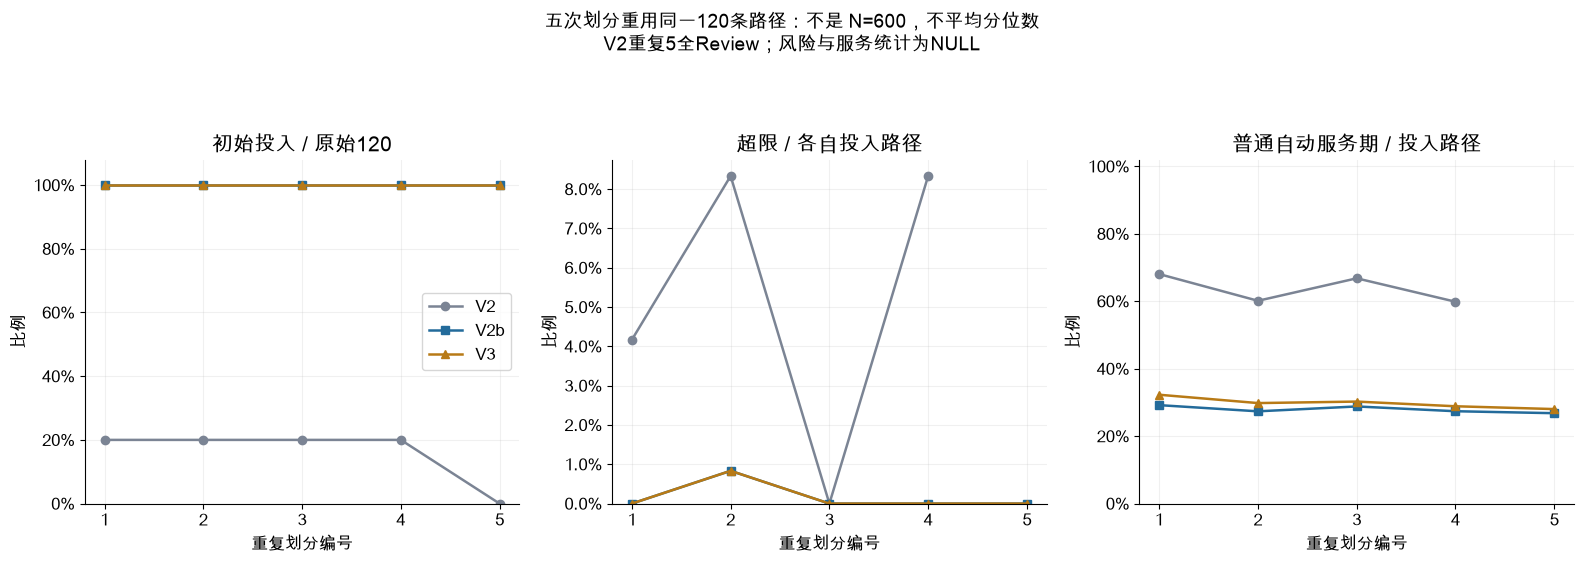

图数据：`03_partition_stability_data.csv`；输入SHA256见同目录 `source_manifest.json`。

,version,repeat_id,financial_n,breach_count,ordinary_service_fraction
0,V2,1,24,1.0,0.6806
1,V2,2,24,2.0,0.6014
2,V2,3,24,0.0,0.6681
3,V2,4,24,2.0,0.5986
4,V2,5,0,NaN,NaN
5,V2b,1,120,0.0,0.2919
6,V2b,2,120,1.0,0.2736
7,V2b,3,120,0.0,0.2881
8,V2b,4,120,0.0,0.2739
9,V2b,5,120,0.0,0.2681


In [6]:
d=tables['repeats'];fig,axes=plt.subplots(1,3,figsize=(16,5.2))
for version,marker in [('V2','o'),('V2b','s'),('V3','^')]:
    q=d[d.version==version].sort_values('repeat_id')
    for ax,key in zip(axes,['initial_coverage','breach_fraction','ordinary_service_fraction']):
        ax.plot(q.repeat_id,q[key],marker=marker,color=colors[version],label=version,lw=1.8)
for ax,title in zip(axes,['初始投入 / 原始120','超限 / 各自投入路径','普通自动服务期 / 投入路径']):
    ax.set(xticks=range(1,6),xlabel='重复划分编号',ylabel='比例',title=title);ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylim(0,1.08);axes[2].set_ylim(0,1.02);axes[1].set_ylim(bottom=0)
axes[0].legend()
fig.suptitle('五次划分重用同一120条路径：不是 N=600，不平均分位数\nV2重复5全Review；风险与服务统计为NULL',fontsize=14,y=1.08)
finish(fig,'03_partition_stability',d)
display(d[['version','repeat_id','financial_n','breach_count','ordinary_service_fraction']].round(4))


### 4. 普通服务在第几年结束

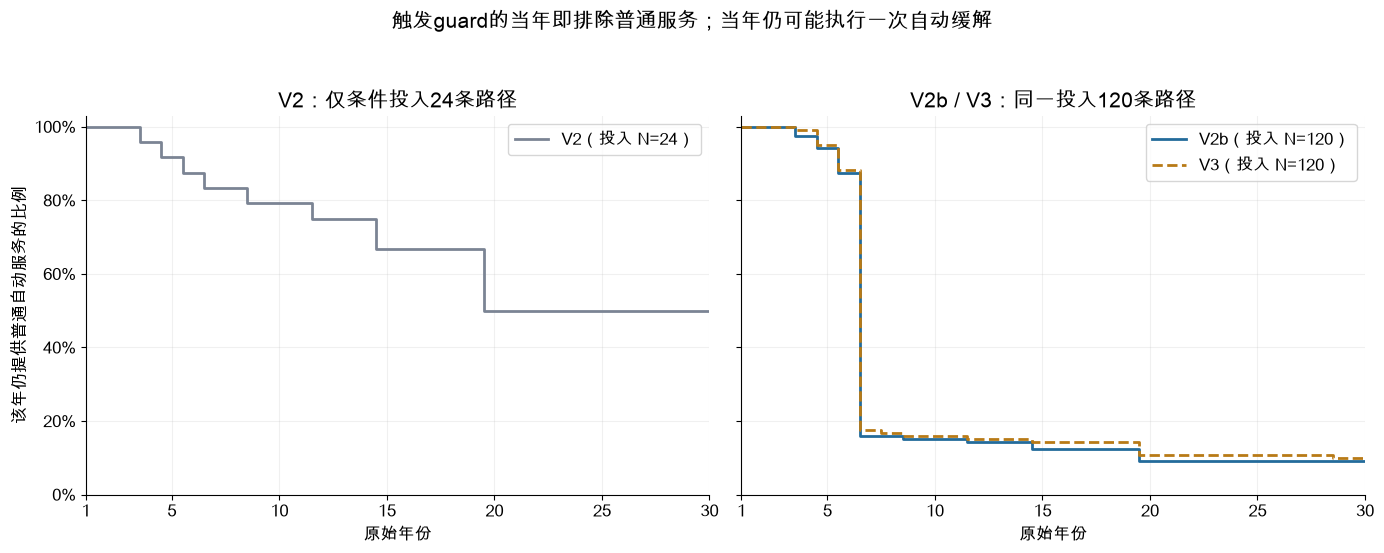

图数据：`04_ordinary_service_data.csv`；输入SHA256见同目录 `source_manifest.json`。

In [7]:
d=tables['ordinary'];fig,axes=plt.subplots(1,2,figsize=(14,5.3),sharey=True)
for version in ['V2','V2b','V3']:
    q=d[d.version==version];ax=axes[0] if version=='V2' else axes[1]
    ax.step(q.year,q.ordinary_service_fraction,where='mid',color=colors[version],label=f"{version}（投入 N={int(q.financial_n.iloc[0])}）",ls='--' if version=='V3' else '-',lw=2)
for ax,title in zip(axes,['V2：仅条件投入24条路径','V2b / V3：同一投入120条路径']):
    ax.set(xlim=(1,30),xticks=[1,5,10,15,20,25,30],ylim=(0,1.03),xlabel='原始年份',title=title);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend()
axes[0].set_ylabel('该年仍提供普通自动服务的比例')
fig.suptitle('触发guard的当年即排除普通服务；当年仍可能执行一次自动缓解',fontsize=15,y=1.04)
finish(fig,'04_ordinary_service',d)


### 5. 费用与预测假设的压力检查

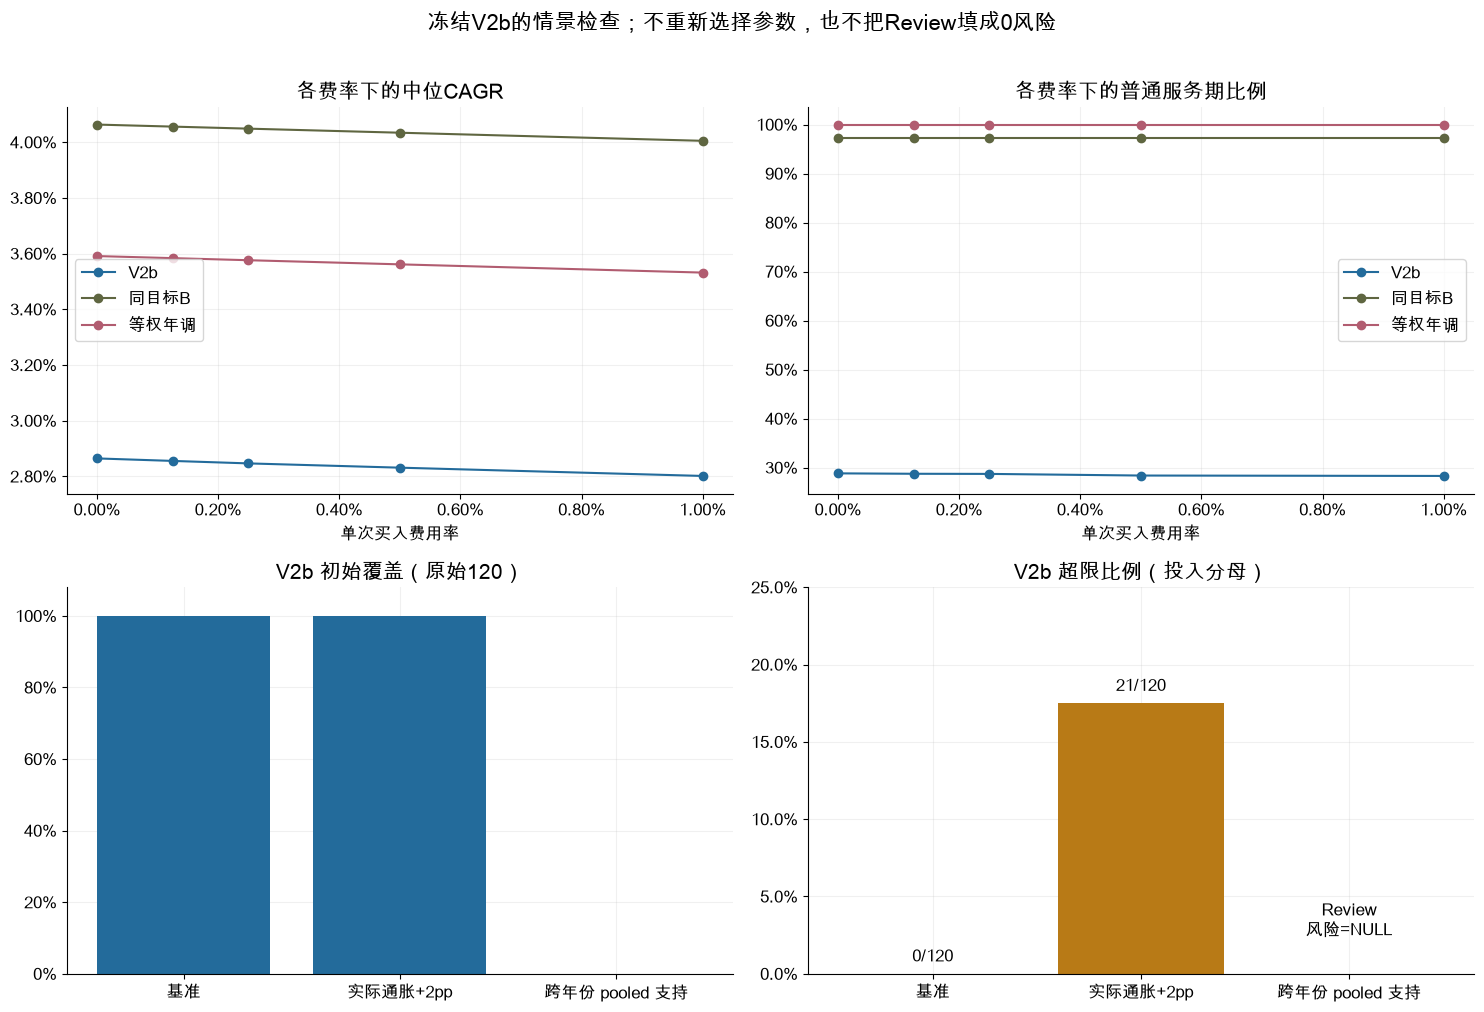

图数据：`05_stress_data.csv`；输入SHA256见同目录 `source_manifest.json`。

**状态：** 完成并独立核验。实际通胀平移属于假设改变；pooled支持属于更保守的独立压力情景，不是事后补救主规则。

In [8]:
fig,axes=plt.subplots(2,2,figsize=(15,10))
if 'stress' not in tables:
    plt.close(fig);fig,ax=plt.subplots(figsize=(12,2.8));ax.axis('off')
    ax.text(.03,.6,'V2b压力结果等待独立审计；本次不展示未审计数值。\n审计完成后重跑本notebook，将补齐费用、通胀与pooled支持三个情景。',transform=ax.transAxes,fontsize=15)
    stress_source=pd.DataFrame([{'status':meta['stress_status']}])
else:
    s=tables['stress'].query('cohort=="outer_OOF"').copy();costs={'fee_0000':0.,'fee_00125':.00125,'base':.0025,'fee_005':.005,'fee_01':.01}
    for policy,label in [('state_budget_learner','V2b'),('same_target_B','同目标B'),('exact_thirds_annual','等权年调')]:
        q=s[(s.policy==policy)&s.setting_id.isin(costs)].copy();q['cost']=q.setting_id.map(costs);q=q.sort_values('cost')
        for ax,key in zip(axes[0],['median_cagr','mean_automatic_fraction']):ax.plot(q.cost,q[key],marker='o',label=label,color=colors[label])
    for ax,title in zip(axes[0],['各费率下的中位CAGR','各费率下的普通服务期比例']):
        ax.set(xlabel='单次买入费用率',title=title);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend()
    q=s.query('policy=="state_budget_learner"').set_index('setting_id').loc[['base','actual_inflation_plus_02','pooled_support']]
    names=['基准','实际通胀+2pp','跨年份 pooled 支持']
    axes[1,0].bar(names,q.initial_coverage,color='#236B9B');axes[1,0].set(title='V2b 初始覆盖（原始120）',ylim=(0,1.08));axes[1,0].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1,1].bar(names,q.breach_fraction,color='#B87A16');axes[1,1].set(title='V2b 超限比例（投入分母）',ylim=(0,.25),xlim=(-.6,2.6),xticks=range(3),xticklabels=names);axes[1,1].yaxis.set_major_formatter(PercentFormatter(1))
    for i,(_,row) in enumerate(q.iterrows()):
        if row.financial_n==0:axes[1,1].text(i,.025,'Review\n风险=NULL',ha='center',fontsize=12)
        else:axes[1,1].text(i,row.breach_fraction+.008,f"{int(row.breach_count)}/{int(row.financial_n)}",ha='center',fontsize=12)
    stress_source=s
fig.suptitle('冻结V2b的情景检查；不重新选择参数，也不把Review填成0风险',fontsize=16,y=1.01)
finish(fig,'05_stress',stress_source)
display(Markdown('**状态：** '+meta['stress_status']+'。实际通胀平移属于假设改变；pooled支持属于更保守的独立压力情景，不是事后补救主规则。'))


### 6. Q1 的权重不是三个独立区间

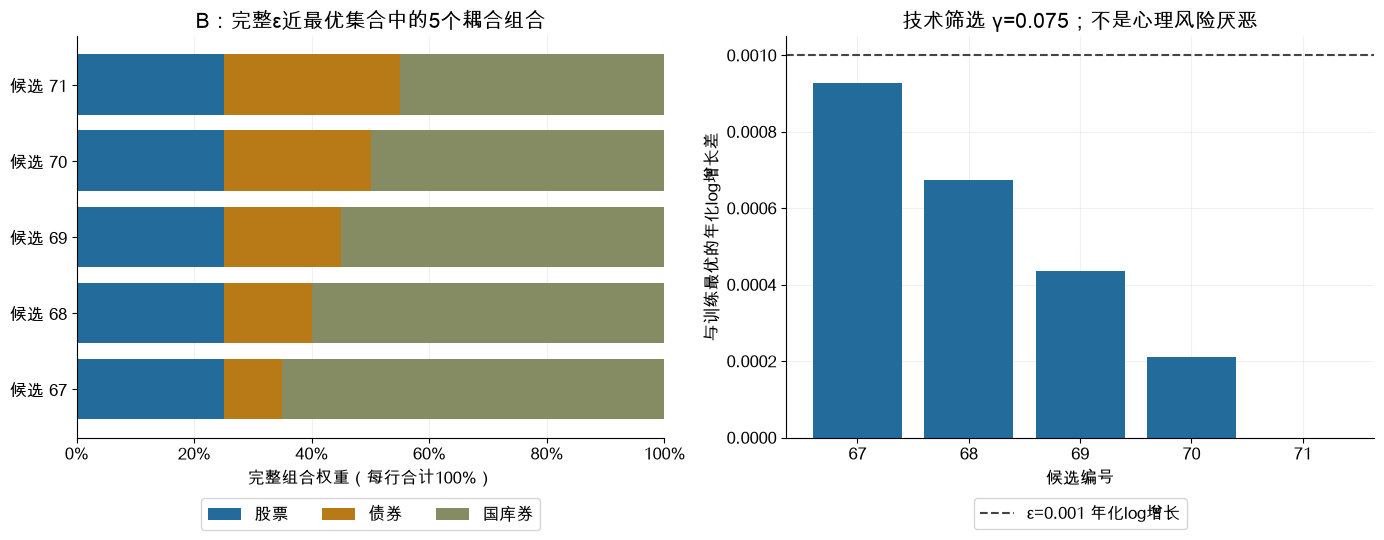

图数据：`06_q1_coupled_weights_data.csv`；输入SHA256见同目录 `source_manifest.json`。

这是B原始15年目标的静态个体可行集诊断，省略共同三产品限制；不能用它替换冻结菜单，也不能从每列最小/最大自由拼接新权重。ε是年化log增长差，不是CAGR差0.1个百分点。

In [9]:
d=tables['near'].sort_values('candidate_local_index');fig,axes=plt.subplots(1,2,figsize=(14,5.6));x=np.arange(len(d));bottom=np.zeros(len(d))
for key,label,color in [('equity','股票','#236B9B'),('bond','债券','#B87A16'),('bill','国库券','#858B62')]:
    axes[0].barh(x,d[key],left=bottom,label=label,color=color);bottom+=d[key].to_numpy()
axes[0].set(yticks=x,yticklabels=[f"候选 {int(v)}" for v in d.candidate_local_index],xlabel='完整组合权重（每行合计100%）',title='B：完整ε近最优集合中的5个耦合组合',xlim=(0,1));axes[0].xaxis.set_major_formatter(PercentFormatter(1));axes[0].legend(ncol=3,loc='upper center',bbox_to_anchor=(.5,-.13))
axes[1].bar(x,d.gap_to_individual_best,color='#236B9B');axes[1].axhline(.001,color='#444444',ls='--',label='ε=0.001 年化log增长');axes[1].set(xticks=x,xticklabels=[str(int(v)) for v in d.candidate_local_index],xlabel='候选编号',ylabel='与训练最优的年化log增长差',title=f"技术筛选 γ={meta['B_full_gamma']:g}；不是心理风险厌恶")
axes[1].legend(loc='upper center',bbox_to_anchor=(.5,-.13));finish(fig,'06_q1_coupled_weights',d)
display(Markdown('这是B原始15年目标的静态个体可行集诊断，省略共同三产品限制；不能用它替换冻结菜单，也不能从每列最小/最大自由拼接新权重。ε是年化log增长差，不是CAGR差0.1个百分点。'))


### Q1各自原始期限：Review保留NULL

Q1为静态年度参考；不能把它的有效分配当作Q2自动执行准入。分位数是各自已投入情景的经验分布统计。

In [10]:
q=tables['q1'].rename(columns={'profile':'客户','horizon':'原H','financial_n':'投入数','review_n':'Review数','breach_count':'超限数','median_cagr':'中位CAGR','p10_cagr':'P10 CAGR','p90_mdd':'P90 MDD'}); display(q.style.format({'L':'{:.0%}','中位CAGR':'{:.2%}','P10 CAGR':'{:.2%}','P90 MDD':'{:.2%}'},na_rep='NULL'))

,客户,原H,L,投入数,Review数,超限数,中位CAGR,P10 CAGR,P90 MDD
0,A,5,10%,0,120,NULL,NULL,NULL,NULL
1,B,15,25%,120,0,9.000000,3.06%,0.12%,24.22%
2,C,30,40%,120,0,9.000000,4.00%,1.39%,38.20%
3,D,25,15%,0,120,NULL,NULL,NULL,NULL
4,E,6,35%,120,0,6.000000,5.00%,-3.69%,31.18%


### 7. 目标券份额与年末漂移

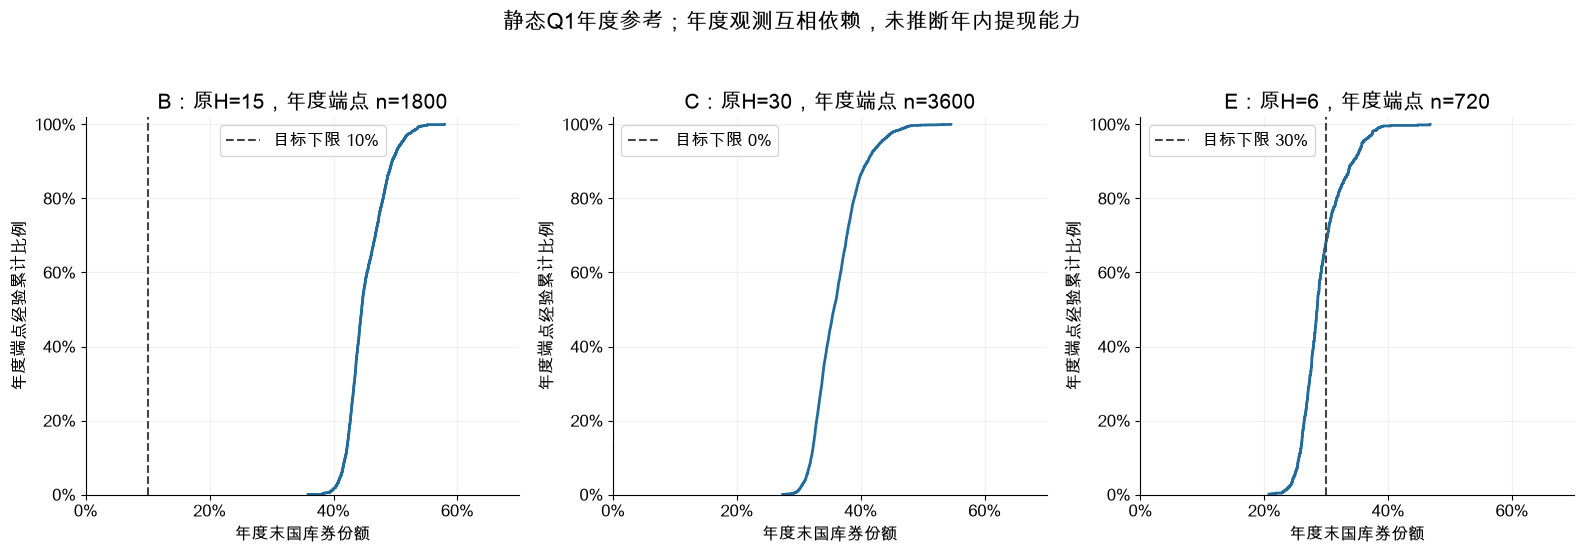

图数据：`07_bill_floor_drift_data.csv`；输入SHA256见同目录 `source_manifest.json`。

,profile,horizon,financial_n,review_n,mean_fraction_end_below_target_floor,maximum_hypothetical_liquidation_drag
0,A,5,0,120,NaN,NaN
1,B,15,120,0,0.00000,0.00160
2,C,30,120,0,0.00000,0.00181
3,D,25,0,120,NaN,NaN
4,E,6,120,0,0.68611,0.00198


A/D为Review，没有金融数值或年度端点。年末低于目标券下限是漂移，不等于原始目标违反下限。假想全转券费用只计容量比值，未从投资路径再次扣除。

In [11]:
d=tables['liquidity'];fig,axes=plt.subplots(1,3,figsize=(16,5.3))
for ax,profile in zip(axes,['B','C','E']):
    q=d[d.profile==profile];summary=tables['liquidity_summary'].query('profile==@profile').iloc[0]
    v=np.sort(q.end_bill_share);ax.step(v,np.arange(1,len(v)+1)/len(v),where='post',color='#236B9B',lw=2)
    ax.axvline(summary.target_floor,color='#444444',ls='--',label=f"目标下限 {summary.target_floor:.0%}")
    ax.set(title=f"{profile}：原H={int(summary.horizon)}，年度端点 n={len(q)}",xlabel='年度末国库券份额',ylabel='年度端点经验累计比例',ylim=(0,1.02),xlim=(0,.7),xticks=[0,.2,.4,.6]);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend()
fig.suptitle('静态Q1年度参考；年度观测互相依赖，未推断年内提现能力',fontsize=16,y=1.04)
finish(fig,'07_bill_floor_drift',d)
display(tables['liquidity_summary'][['profile','horizon','financial_n','review_n','mean_fraction_end_below_target_floor','maximum_hypothetical_liquidation_drag']].round(5))
display(Markdown('A/D为Review，没有金融数值或年度端点。年末低于目标券下限是漂移，不等于原始目标违反下限。假想全转券费用只计容量比值，未从投资路径再次扣除。'))


### 8. 事前规则选出的严重合成案例

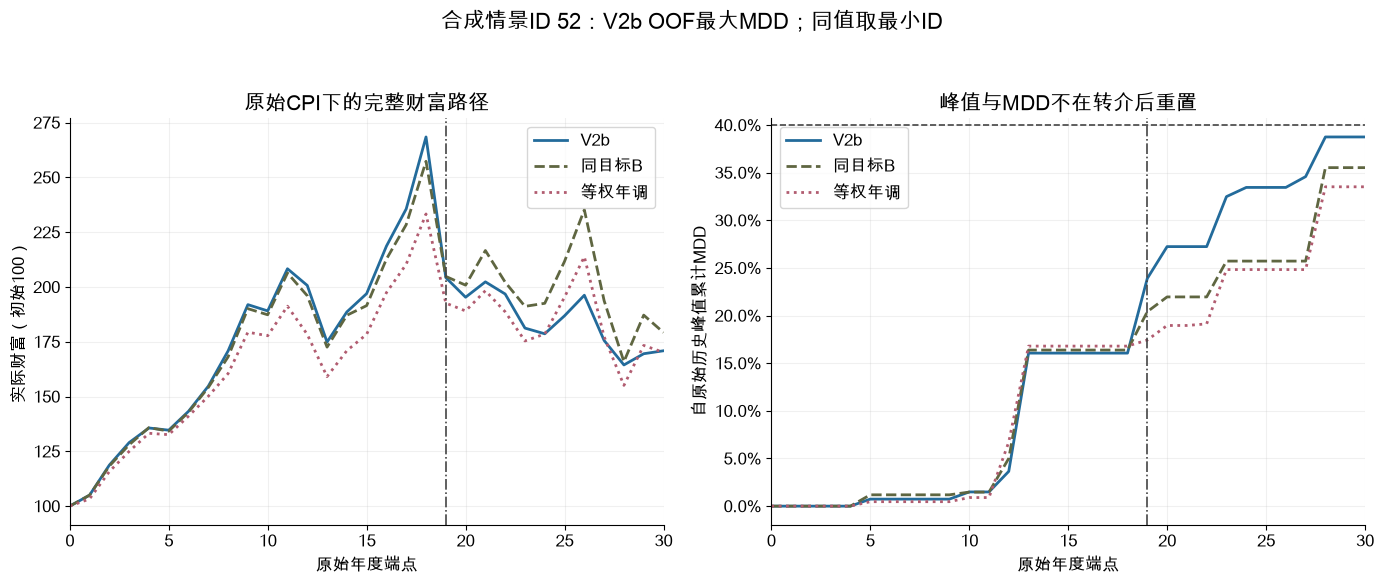

图数据：`08_severe_synthetic_path_data.csv`；输入SHA256见同目录 `source_manifest.json`。

点划线为guard触发的决策时刻（第20年开始前）。这是按固定最大MDD规则选取的合成案例，不是历史危机事件或随机代表情景。

In [12]:
d=tables['severe'];fig,axes=plt.subplots(1,2,figsize=(14,5.6))
for label,ls in [('V2b','-'),('同目标B','--'),('等权年调',':')]:
    q=d[d.series==label]
    axes[0].plot(q.endpoint,q.real_wealth,label=label,color=colors[label],ls=ls,lw=2)
    axes[1].plot(q.endpoint,q.running_mdd,label=label,color=colors[label],ls=ls,lw=2)
for ax in axes:
    ax.set(xlim=(0,30),xticks=[0,5,10,15,20,25,30],xlabel='原始年度端点');ax.legend()
    if meta['severe_first_guard']>0:ax.axvline(meta['severe_first_guard']-1,color='#444444',ls='-.',lw=1.2)
axes[0].set(ylabel='实际财富（初始100）',title='原始CPI下的完整财富路径')
axes[1].set(ylabel='自原始历史峰值累计MDD',title='峰值与MDD不在转介后重置');axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].axhline(.4,color='#444444',ls='--',lw=1.2)
fig.suptitle(f"合成情景ID {meta['severe_id']}：V2b OOF最大MDD；同值取最小ID",fontsize=16,y=1.04)
finish(fig,'08_severe_synthetic_path',d)
display(Markdown(f"点划线为guard触发的决策时刻（第{meta['severe_first_guard']}年开始前）。这是按固定最大MDD规则选取的合成案例，不是历史危机事件或随机代表情景。"))


### 9. 有限提案失败与宽持仓可行性分开

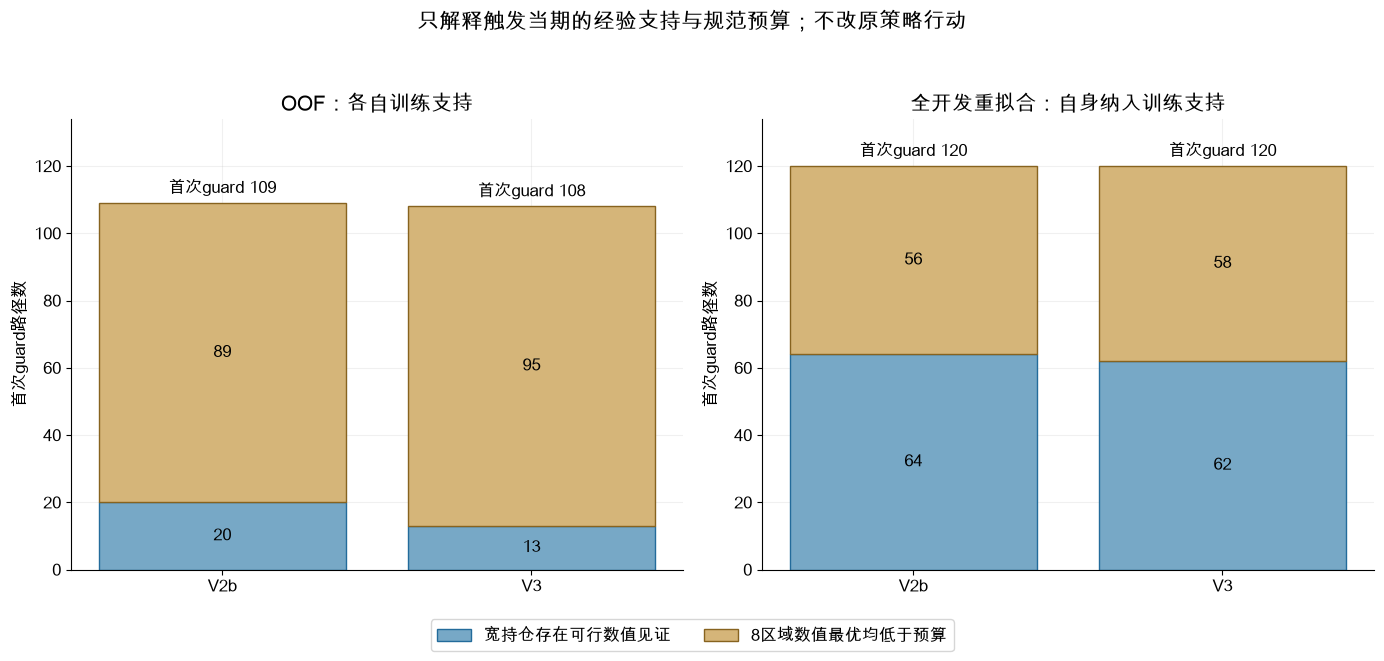

图数据：`09_guard_physical_feasibility_data.csv`；输入SHA256见同目录 `source_manifest.json`。

**关键判断：** OOF中，V2b的109次首次guard里20次存在更宽持仓的可行数值见证，V3为13/108；有限提案失败不能一概归为物理不可行。其余89/95次获得全部8个买卖区域的数值证书，表明该次训练支持下最优值仍低于预算。证书经过独立代数与KKT检查，但不是精确算术不可能性证明，也不是未来市场保证。全开发结果与OOF分开展示，不能合并成新的独立样本。

,version,scope,first_guard_n,numerical_physical_feasible_witness_above_budget,all_eight_numerical_optima_below_budget,numerical_boundary_unresolved,incomplete_solver_or_certificate_evidence,solver_or_certificate_unresolved
0,V2b,outer_selected,109,20,89,0,0,0
1,V2b,full_selected,120,64,56,0,0,0
2,V3,outer_selected,108,13,95,0,0,0
3,V3,full_selected,120,62,58,0,0,0


In [13]:
d=tables['physical_feasibility'];fig,axes=plt.subplots(1,2,figsize=(14,5.8))
keys=['numerical_physical_feasible_witness_above_budget','all_eight_numerical_optima_below_budget']
for ax,scope,title in zip(axes,['outer_selected','full_selected'],['OOF：各自训练支持','全开发重拟合：自身纳入训练支持']):
    q=d[d.scope==scope].set_index('version').loc[['V2b','V3']];x=np.arange(2)
    feasible=q[keys[0]];below=q[keys[1]]
    ax.bar(x,feasible,color='#77A8C6',edgecolor='#236B9B',label='宽持仓存在可行数值见证')
    ax.bar(x,below,bottom=feasible,color='#D5B579',edgecolor='#87631F',label='8区域数值最优均低于预算')
    for i,v in enumerate(q.index):
        ax.text(i,feasible.loc[v]/2,str(int(feasible.loc[v])),ha='center',va='center')
        ax.text(i,feasible.loc[v]+below.loc[v]/2,str(int(below.loc[v])),ha='center',va='center')
        ax.text(i,q.loc[v,'first_guard_n']+3,f"首次guard {int(q.loc[v,'first_guard_n'])}",ha='center')
    ax.set(xticks=x,xticklabels=['V2b','V3'],ylim=(0,134),ylabel='首次guard路径数',title=title)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.5,-.08),ncol=2)
fig.suptitle('只解释触发当期的经验支持与规范预算；不改原策略行动',fontsize=16,y=1.04)
finish(fig,'09_guard_physical_feasibility',d)
display(Markdown('**关键判断：** OOF中，V2b的109次首次guard里20次存在更宽持仓的可行数值见证，V3为13/108；有限提案失败不能一概归为物理不可行。其余89/95次获得全部8个买卖区域的数值证书，表明该次训练支持下最优值仍低于预算。证书经过独立代数与KKT检查，但不是精确算术不可能性证明，也不是未来市场保证。全开发结果与OOF分开展示，不能合并成新的独立样本。'))
display(d[['version','scope','first_guard_n',*keys,'numerical_boundary_unresolved','incomplete_solver_or_certificate_evidence','solver_or_certificate_unresolved']])


### 10. 一步预测诊断与完整策略结果相互区分

资产MSE每个OOF市场/年份只出现一次，不因服务拒绝而删行；策略预测只在有效决策时存在。成员与决策分别聚合，先按情景平均。缓解行动的配对增长分数只是注释，实际排序目标是支持最坏财富。

In [14]:
display(tables['prediction'].round(6))

,version,unit,phase,forecast,metric,value
0,V2,资产均值预测,positive_period,uniform,标准化MSE,1.057328
1,V2,资产均值预测,positive_period,shrink_conditional,标准化MSE,1.053525
2,V2,已投入策略一步,growth,uniform,配对收益RMSE,0.017875
3,V2,已投入策略一步,protection,uniform,配对收益RMSE,0.039103
4,V2b,资产均值预测,positive_period,uniform,标准化MSE,1.057328
5,V2b,资产均值预测,positive_period,shrink_conditional,标准化MSE,1.053525
6,V2b,已投入策略一步,growth,uniform,配对收益RMSE,0.021352
7,V2b,已投入策略一步,protection,uniform,配对收益RMSE,0.024390
8,V2b,已投入策略一步,mitigation_trade,uniform,配对收益RMSE,0.040124
9,V3,资产均值预测,positive_period,uniform,标准化MSE,1.057328


### 11. 流动性容量的适用边界

年度末假想全转券拖累为 `drag=c·(1−s_bill)/(1+c)`，`capacity=1−drag`。这笔假想手续费没有从投资路径再次扣除；它不是客户支出计划、年内流动性承诺，也不是第9节联合支持预算可行性的另一种说法。

## Takeaways

1. 保留负面结果：覆盖、普通服务持续性、收益和风险同时报告，不用单一漂亮指标替代。
2. V2与全120投入版本的条件总体不同；同120比较只在明确匹配的V2b/V3及参考中进行。五次划分是同120情景的依赖重复，不是N600。
3. V3增加状态依赖提案，不保证优于V2b；最终技术候选的锁定须结合完整策略、稳定性、成本和复杂度判断。
4. 所有图表都是开发证据，不能抹除历史曝光或声称新盲测。当前文档没有读取最终集。

In [15]:
from build_technical_rebuild_companion import sha
assert all(sha(ROOT/name)==digest for name,digest in meta['sources'].items())
display(Markdown('保存产物在notebook执行前后SHA256一致。所有图已输出PNG 240dpi、可编辑文字SVG与对应CSV。'))

保存产物在notebook执行前后SHA256一致。所有图已输出PNG 240dpi、可编辑文字SVG与对应CSV。